# Best Model Fine-Tuning

LightGBM was the best model in the comparison notebook. Here its hyperparameters are tuned to find the maximum score it can reach.

To get an honest score, the tuning only uses data **before 2015**. The final evaluation is done with data from **2015 onwards**, which the tuning never sees.

## Libraries

In [1]:
from lightgbm import LGBMClassifier
from sklearn.metrics import roc_auc_score, average_precision_score, f1_score, roc_curve, precision_recall_curve

import optuna # Hyperparameter search
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

## Data Loading And Configuration

In [2]:
full_df = pd.read_csv("./dataset.csv")
full_df["date"] = pd.to_datetime(full_df['date'], format='%Y-%m-%d')

np.random.seed(42)

In [3]:
FEATURES = [c for c in full_df.columns if c not in ['date', 'longitude', 'latitude', 'fire']] # Coordinates and date are not used as variables

EMBARGO = pd.Timedelta(days=90) # Same as the longest rolling window, avoids leakage between train and test
TEST_START = 2015 # First year of the final evaluation, everything before is used for the tuning
TUNING_YEARS = range(2012, TEST_START) # Validation years used during the tuning
TEST_YEARS = range(TEST_START, full_df['date'].dt.year.max() + 1)

K = 5 # Number of spatial folds
BLOCK_SIZE = 0.3 # Size (in degrees) of each spatial block

N_TRIALS = 60 # Number of hyperparameter combinations tried

NEG_POS_RATIO = (full_df['fire'] == 0).sum() / (full_df['fire'] == 1).sum() # Used to balance the classes

# Colors used in every plot
BASELINE_COLOR = "#b0b0b0"
TUNED_COLOR = "#2a78d6"

## Validation Splits
---
The same two tests of the comparison notebook (temporal and spatial) are built twice:
- **Tuning splits**: only data before 2015. Temporal validation in 2012, 2013 and 2014 and spatial validation by blocks.
- **Final splits**: temporal validation from 2015 to 2023 and spatial validation by blocks, but testing only with data from 2015 onwards.

In [4]:
year = full_df['date'].dt.year
tuning_data = year < TEST_START # Data available for the tuning

# Lon and lat division in blocks
block_lon = (full_df['longitude'] // BLOCK_SIZE).astype(int)
block_lat = (full_df['latitude'] // BLOCK_SIZE).astype(int)

# Individual block ID for each entry
block_id = block_lon.astype(str) + '_' + block_lat.astype(str)

blocks = np.array(block_id.unique()) # Unique blocks

np.random.shuffle(blocks)

# Replaces blocks ID for fold number
fold = block_id.map(dict(zip(blocks, np.arange(len(blocks)) % K)))


def temporal_splits(years, available):
    return [
        (y,
         available & (full_df['date'] <= pd.Timestamp(f'{y}-01-01') - EMBARGO),
         available & (year == y))
        for y in years
    ]


def spatial_splits(train_rows, test_rows):
    return [(k, train_rows & (fold != k), test_rows & (fold == k)) for k in range(K)]


all_data = pd.Series(True, index=full_df.index)

tuning_splits = {
    'temporal': temporal_splits(TUNING_YEARS, tuning_data),
    'spatial': spatial_splits(tuning_data, tuning_data),
}

final_splits = {
    'temporal': temporal_splits(TEST_YEARS, all_data),
    'spatial': spatial_splits(all_data, ~tuning_data), # Trained with every year, tested only from 2015
}

## Evaluation Function

In [5]:
def evaluate(params, splits, threshold=0.5):
    rows = []
    y_true, y_proba = [], []

    for split, train_idx, test_idx in splits:
        model = LGBMClassifier(**params)
        model.fit(full_df.loc[train_idx, FEATURES], full_df.loc[train_idx, 'fire'])

        y_test = full_df.loc[test_idx, 'fire']
        proba = model.predict_proba(full_df.loc[test_idx, FEATURES])[:, 1]

        rows.append({
            'split': split,
            'roc_auc': roc_auc_score(y_test, proba),
            'pr_auc': average_precision_score(y_test, proba),
            'f1': f1_score(y_test, proba >= threshold),
        })

        y_true.append(y_test.values)
        y_proba.append(proba)

    return pd.DataFrame(rows), np.concatenate(y_true), np.concatenate(y_proba)

## Baseline
---
Same configuration used in the comparison notebook. The tuned model has to beat it.

In [6]:
FIXED_PARAMS = {
    'scale_pos_weight': NEG_POS_RATIO,
    'subsample_freq': 1,
    'random_state': 42,
    'n_jobs': -1,
    'verbose': -1,
}

BASELINE_PARAMS = {
    'n_estimators': 1000,
    'learning_rate': 0.02,
    'num_leaves': 63,
    'min_child_samples': 20,
    'subsample': 0.8,
    'colsample_bytree': 0.7,
    'reg_alpha': 0.0,
    'reg_lambda': 0.0,
}

## Hyperparameter Tuning
---
Optuna is used to explore the hyperparameters. Each combination is scored with the mean ROC-AUC of both tuning tests (temporal and spatial). The baseline is the first combination tried, so the result can only be equal or better.

In [7]:
def objective(trial):
    params = {
        'n_estimators': trial.suggest_int('n_estimators', 200, 2000, step=100),
        'learning_rate': trial.suggest_float('learning_rate', 0.005, 0.1, log=True),
        'num_leaves': trial.suggest_int('num_leaves', 15, 255, log=True), # Complexity of each tree
        'min_child_samples': trial.suggest_int('min_child_samples', 5, 200, log=True), # Minimum samples per leaf
        'subsample': trial.suggest_float('subsample', 0.5, 1.0), # Rows used by each tree
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.3, 1.0), # Variables used by each tree
        'reg_alpha': trial.suggest_float('reg_alpha', 1e-3, 10, log=True), # L1 regularization
        'reg_lambda': trial.suggest_float('reg_lambda', 1e-3, 10, log=True), # L2 regularization
    }

    temporal, _, _ = evaluate(params | FIXED_PARAMS, tuning_splits['temporal'])
    spatial, _, _ = evaluate(params | FIXED_PARAMS, tuning_splits['spatial'])

    # Saved to plot them later
    trial.set_user_attr('temporal_auc', temporal['roc_auc'].mean())
    trial.set_user_attr('spatial_auc', spatial['roc_auc'].mean())

    return (temporal['roc_auc'].mean() + spatial['roc_auc'].mean()) / 2

In [8]:
optuna.logging.set_verbosity(optuna.logging.WARNING) # Avoids one log line per trial

study = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=42))
study.enqueue_trial(BASELINE_PARAMS | {'reg_alpha': 1e-3, 'reg_lambda': 1e-3}) # Baseline as first trial (regularization at its minimum value)
study.optimize(objective, n_trials=N_TRIALS)

BEST_PARAMS = study.best_params

print(f"Baseline tuning AUC: {study.trials[0].value:.4f}")
print(f"Best tuning AUC:     {study.best_value:.4f} (trial {study.best_trial.number})")

Baseline tuning AUC: 0.7786
Best tuning AUC:     0.7838 (trial 50)


In [9]:
pd.DataFrame({'baseline': BASELINE_PARAMS, 'tuned': BEST_PARAMS}).round(4)

,baseline,tuned
n_estimators,1000.00,1700.0000
learning_rate,0.02,0.0051
num_leaves,63.00,213.0000
min_child_samples,20.00,17.0000
subsample,0.80,0.9805
colsample_bytree,0.70,0.3040
reg_alpha,0.00,0.0033
reg_lambda,0.00,0.0030


#### Tuning History
Each point is one combination of hyperparameters, the line is the best score found until that moment.

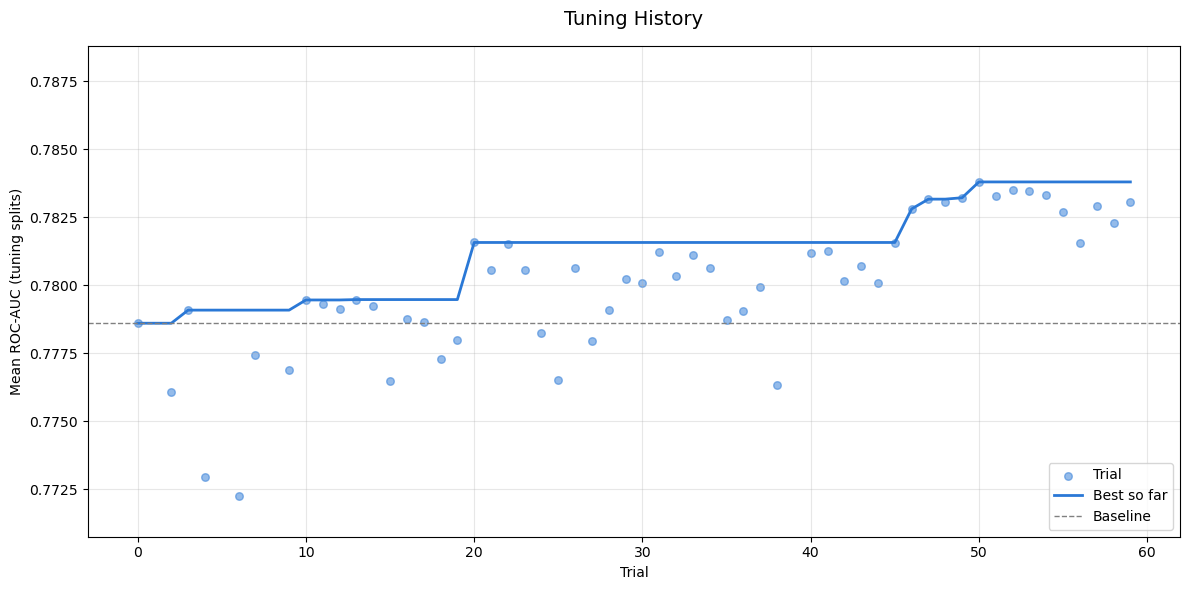

In [10]:
trials = study.trials_dataframe()

fig, ax = plt.subplots(figsize=(12, 6))

ax.scatter(trials['number'], trials['value'], color=TUNED_COLOR, alpha=0.5, s=30, label='Trial')
ax.plot(trials['number'], trials['value'].cummax(), color=TUNED_COLOR, lw=2, label='Best so far')
ax.axhline(study.trials[0].value, ls='--', color='gray', lw=1, label='Baseline')

ax.set_xlabel("Trial")
ax.set_ylabel("Mean ROC-AUC (tuning splits)")
ax.set_title("Tuning History", fontsize=14, pad=15)
ax.set_ylim(trials['value'].quantile(0.1) - 0.005, trials['value'].max() + 0.005) # Hides the worst trials to focus on the best ones
ax.grid(alpha=0.3)
ax.legend(loc='lower right')

plt.tight_layout()
plt.show()

#### Hyperparameter Influence
Relation between each hyperparameter and the score obtained.

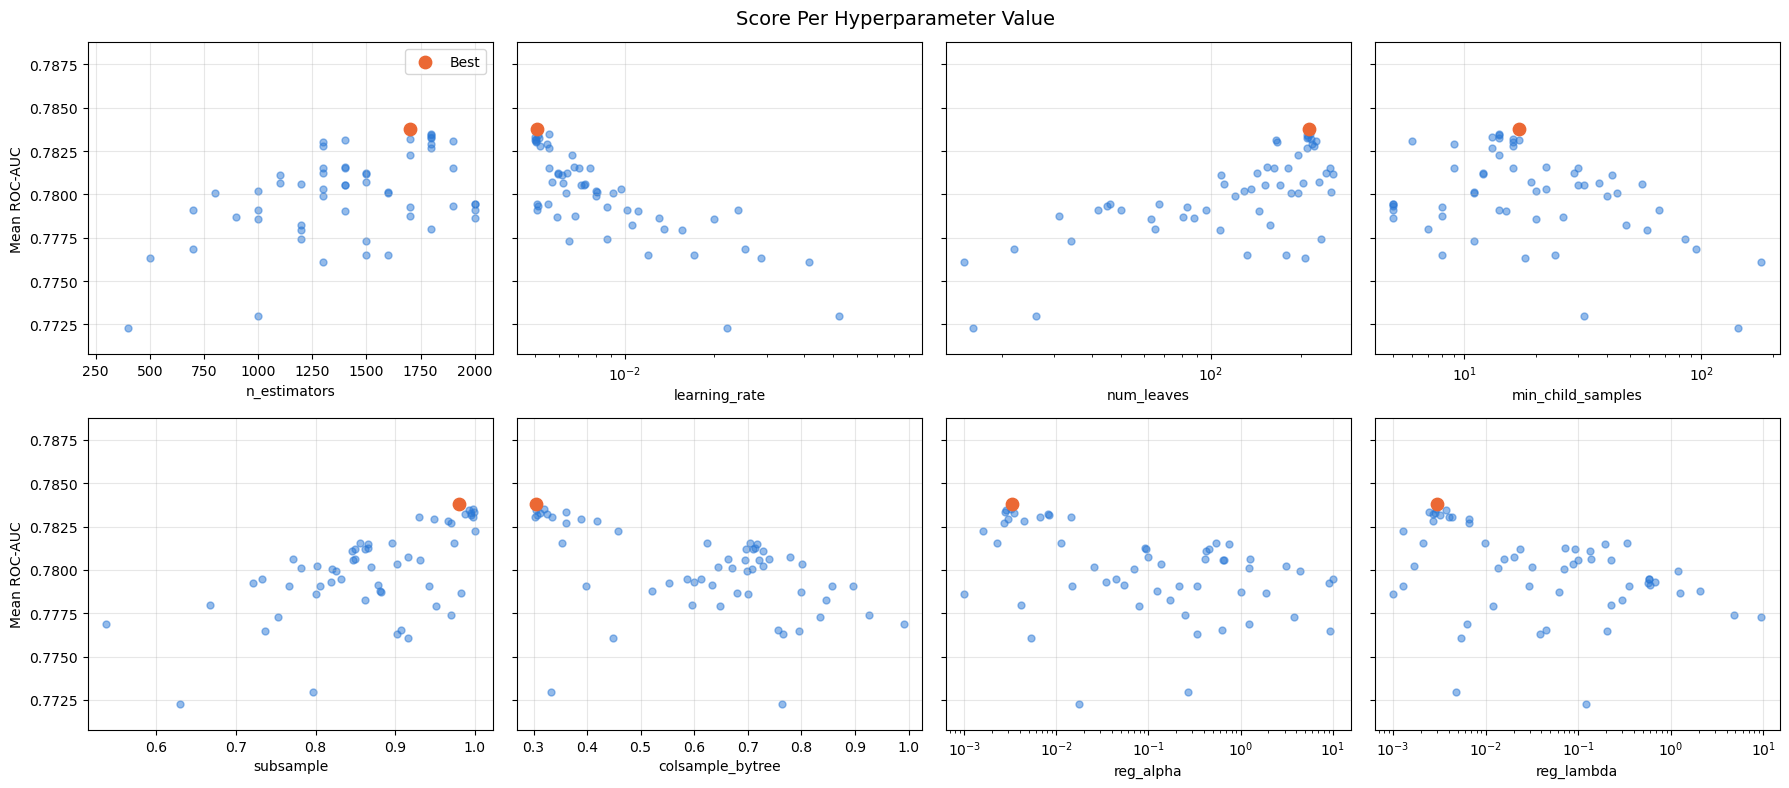

In [11]:
param_cols = [f'params_{p}' for p in BEST_PARAMS]
log_params = ['learning_rate', 'num_leaves', 'min_child_samples', 'reg_alpha', 'reg_lambda'] # Searched in log scale

fig, axes = plt.subplots(2, 4, figsize=(18, 8), sharey=True)

for ax, col in zip(axes.flat, param_cols):
    name = col.replace('params_', '')
    ax.scatter(trials[col], trials['value'], color=TUNED_COLOR, alpha=0.5, s=25)
    ax.scatter(BEST_PARAMS[name], study.best_value, color='#eb6834', s=80, zorder=3, label='Best')

    if name in log_params:
        ax.set_xscale('log')

    ax.set_xlabel(name)
    ax.set_ylim(trials['value'].quantile(0.1) - 0.005, trials['value'].max() + 0.005)
    ax.grid(alpha=0.3)

axes[0, 0].set_ylabel("Mean ROC-AUC")
axes[1, 0].set_ylabel("Mean ROC-AUC")
axes[0, 0].legend()

fig.suptitle("Score Per Hyperparameter Value", fontsize=14)
plt.tight_layout()
plt.show()

## Decision Threshold
---
ROC-AUC doesn't depend on the threshold, but to predict "fire / no fire" one is needed. Instead of the default 0.5, the threshold that maximizes F1 is chosen using the predictions of the tuning splits (never the final test).

In [12]:
TUNED_PARAMS = BEST_PARAMS | FIXED_PARAMS
BASELINE_FULL_PARAMS = BASELINE_PARAMS | FIXED_PARAMS

# Predictions of the tuned model in every tuning split
y_true, y_proba = [], []
for scheme in ['temporal', 'spatial']:
    _, t, p = evaluate(TUNED_PARAMS, tuning_splits[scheme])
    y_true.append(t)
    y_proba.append(p)

precision, recall, thresholds = precision_recall_curve(np.concatenate(y_true), np.concatenate(y_proba))
f1_values = 2 * precision * recall / (precision + recall + 1e-12)

THRESHOLD = thresholds[np.argmax(f1_values[:-1])] # Last precision / recall value has no threshold

print(f"Best threshold: {THRESHOLD:.3f} (F1 = {f1_values[:-1].max():.3f} in the tuning splits)")

Best threshold: 0.369 (F1 = 0.621 in the tuning splits)


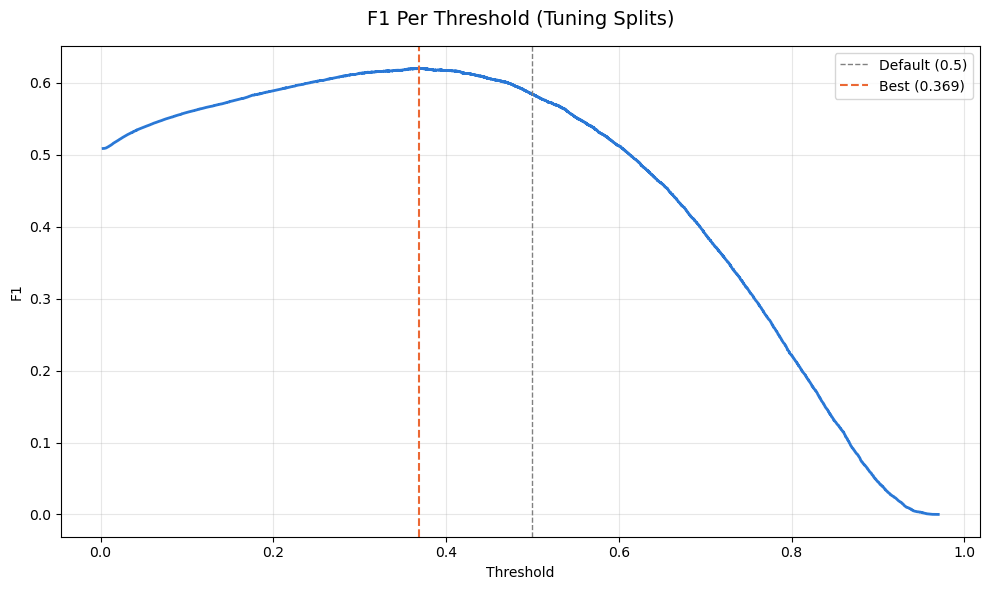

In [13]:
fig, ax = plt.subplots(figsize=(10, 6))

ax.plot(thresholds, f1_values[:-1], color=TUNED_COLOR, lw=2)
ax.axvline(0.5, ls='--', color='gray', lw=1, label='Default (0.5)')
ax.axvline(THRESHOLD, ls='--', color='#eb6834', lw=1.5, label=f'Best ({THRESHOLD:.3f})')

ax.set_xlabel("Threshold")
ax.set_ylabel("F1")
ax.set_title("F1 Per Threshold (Tuning Splits)", fontsize=14, pad=15)
ax.grid(alpha=0.3)
ax.legend()

plt.tight_layout()
plt.show()

## Final Evaluation
---
Both models (baseline and tuned) are evaluated in the final splits. F1 is computed with the 0.5 threshold for the baseline and with the chosen threshold for the tuned model.

In [14]:
results = [] # One row per model, test and split
predictions = {} # Predictions of every split joined, used for the ROC curves

for name, params, threshold in [('Baseline', BASELINE_FULL_PARAMS, 0.5), ('Tuned', TUNED_PARAMS, THRESHOLD)]:
    for scheme, splits in final_splits.items():
        metrics, y_true, y_proba = evaluate(params, splits, threshold)
        metrics['model'] = name
        metrics['scheme'] = scheme

        results.append(metrics)
        predictions[(name, scheme)] = (y_true, y_proba)

results = pd.concat(results, ignore_index=True)

summary = results.groupby(['scheme', 'model'])[['roc_auc', 'pr_auc', 'f1']].agg(['mean', 'std'])
summary.loc[['temporal', 'spatial']].round(3)

roc_auc        pr_auc            f1       
                     mean    std   mean    std   mean    std
scheme   model                                              
temporal Baseline   0.797  0.025  0.651  0.038  0.612  0.026
         Tuned      0.803  0.025  0.659  0.038  0.613  0.029
spatial  Baseline   0.763  0.012  0.603  0.036  0.575  0.038
         Tuned      0.767  0.013  0.613  0.037  0.590  0.031

In [15]:
# Gain of the tuned model over the baseline
means = results.groupby(['scheme', 'model'])[['roc_auc', 'pr_auc', 'f1']].mean()
(means.xs('Tuned', level='model') - means.xs('Baseline', level='model')).loc[['temporal', 'spatial']].round(4)

,roc_auc,pr_auc,f1
scheme,,,
temporal,0.0055,0.0079,0.0011
spatial,0.0042,0.0092,0.0154


#### Metrics Comparison
Error bars show the standard deviation between years / folds.

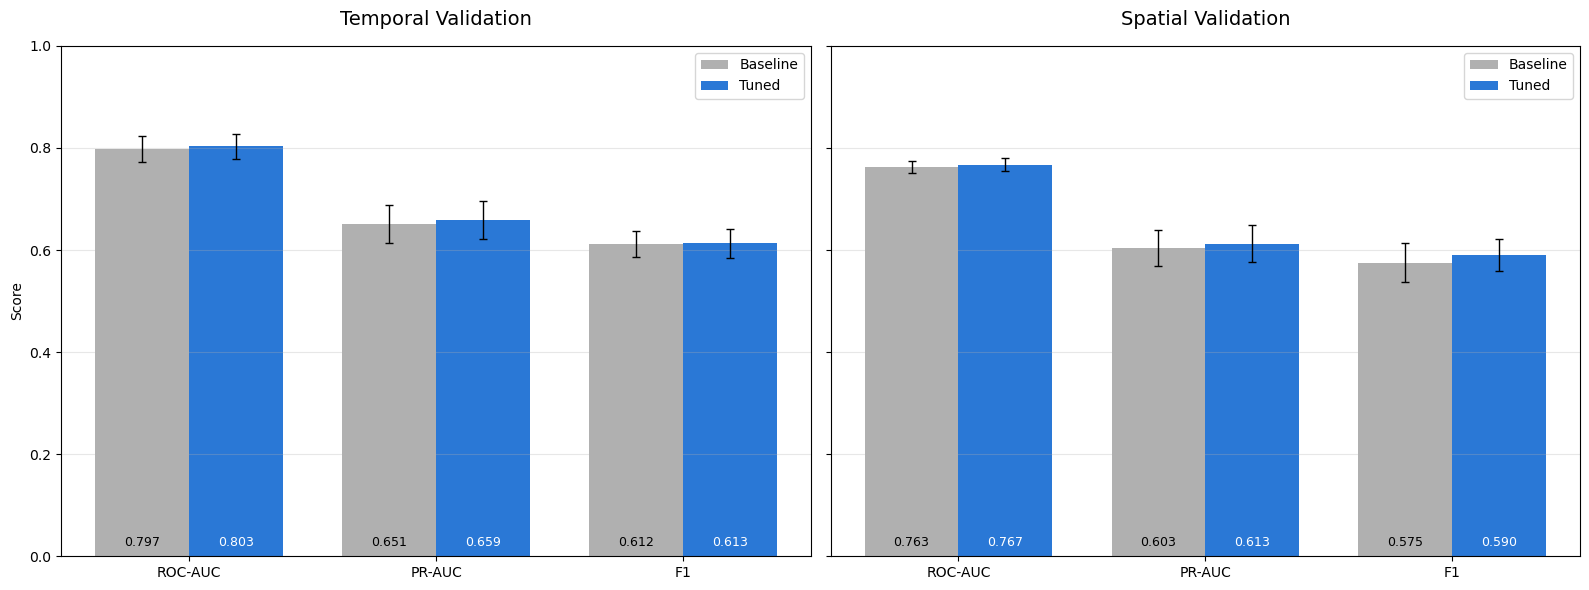

In [16]:
METRICS = {'roc_auc': 'ROC-AUC', 'pr_auc': 'PR-AUC', 'f1': 'F1'}

fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharey=True)

for ax, scheme in zip(axes, ['temporal', 'spatial']):
    x = np.arange(len(METRICS))
    width = 0.38

    for offset, model, color in [(-width / 2, 'Baseline', BASELINE_COLOR), (width / 2, 'Tuned', TUNED_COLOR)]:
        mean = summary.loc[(scheme, model), [(m, 'mean') for m in METRICS]].values
        std = summary.loc[(scheme, model), [(m, 'std') for m in METRICS]].values
        ax.bar(x + offset, mean, width, yerr=std, color=color, label=model, capsize=3, error_kw={'lw': 1})

        for xi, value in zip(x + offset, mean):
            ax.text(xi, 0.02, f"{value:.3f}", ha='center', fontsize=9, color='white' if model == 'Tuned' else 'black')

    ax.set_xticks(x, METRICS.values())
    ax.set_ylim(0, 1)
    ax.set_title(f"{scheme.capitalize()} Validation", fontsize=14, pad=15)
    ax.grid(axis='y', alpha=0.3)
    ax.legend(loc='upper right')

axes[0].set_ylabel("Score")

plt.tight_layout()
plt.show()

#### ROC-AUC Per Year And Per Fold

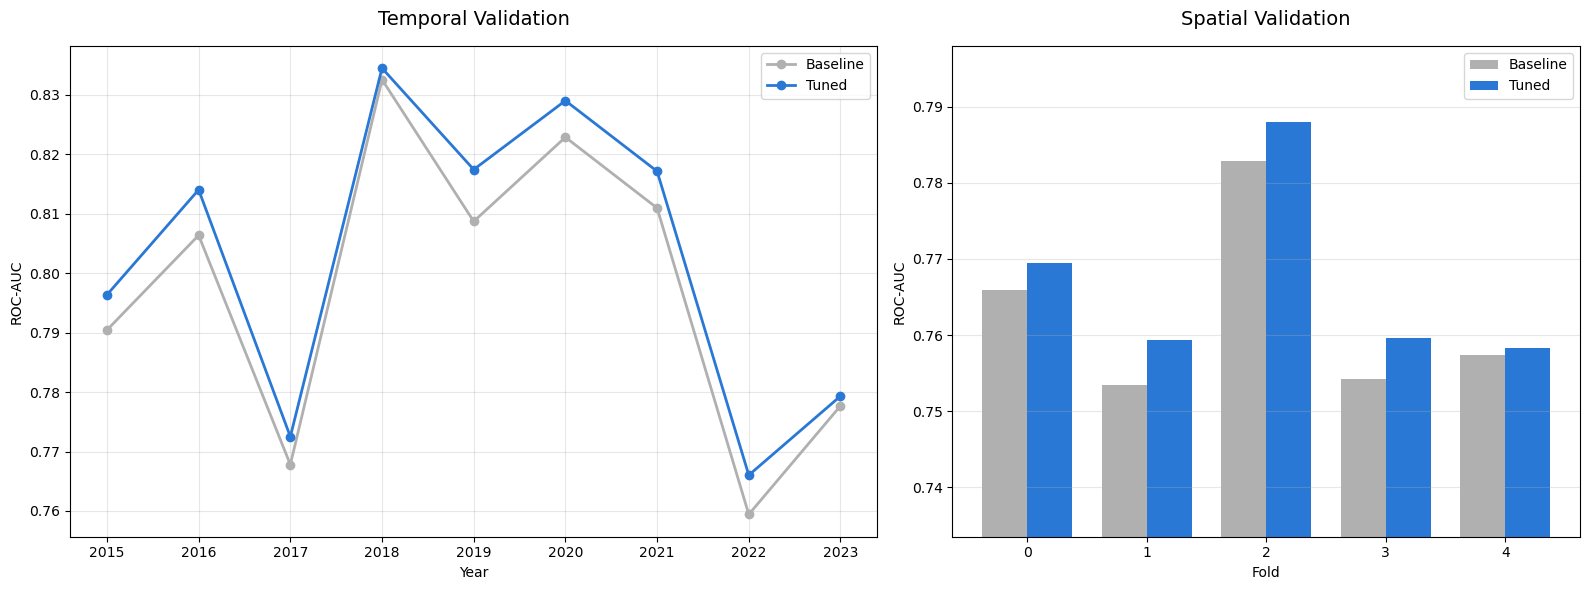

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6), gridspec_kw={'width_ratios': [len(TEST_YEARS), K + 2]})

temporal = results[results['scheme'] == 'temporal'].pivot(index='split', columns='model', values='roc_auc')
spatial = results[results['scheme'] == 'spatial'].pivot(index='split', columns='model', values='roc_auc')

for model, color in [('Baseline', BASELINE_COLOR), ('Tuned', TUNED_COLOR)]:
    axes[0].plot(temporal.index, temporal[model], marker='o', lw=2, color=color, label=model)

axes[0].set_xlabel("Year")
axes[0].set_ylabel("ROC-AUC")
axes[0].set_title("Temporal Validation", fontsize=14, pad=15)
axes[0].grid(alpha=0.3)
axes[0].legend()

spatial[['Baseline', 'Tuned']].plot(kind='bar', ax=axes[1], rot=0, color=[BASELINE_COLOR, TUNED_COLOR], width=0.75)
axes[1].set_xlabel("Fold")
axes[1].set_ylabel("ROC-AUC")
axes[1].set_ylim(spatial.min().min() - 0.02, spatial.max().max() + 0.01) # Zoom on the differences
axes[1].set_title("Spatial Validation", fontsize=14, pad=15)
axes[1].grid(axis='y', alpha=0.3)
axes[1].legend(title="")

plt.tight_layout()
plt.show()

#### ROC Curves

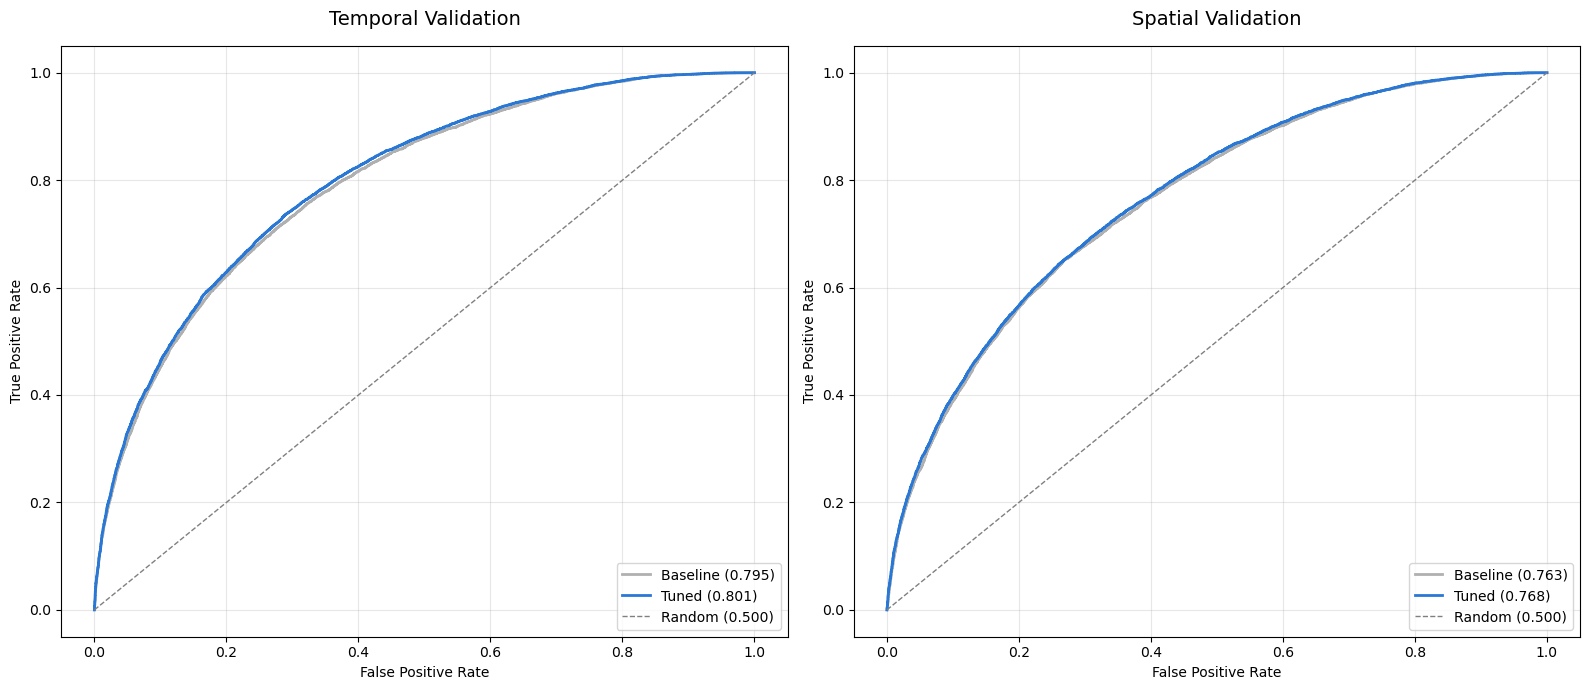

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

for ax, scheme in zip(axes, ['temporal', 'spatial']):
    for model, color in [('Baseline', BASELINE_COLOR), ('Tuned', TUNED_COLOR)]:
        y_true, y_proba = predictions[(model, scheme)]
        fpr, tpr, _ = roc_curve(y_true, y_proba)
        ax.plot(fpr, tpr, color=color, lw=2, label=f"{model} ({roc_auc_score(y_true, y_proba):.3f})")

    ax.plot([0, 1], [0, 1], ls='--', color='gray', lw=1, label='Random (0.500)')

    ax.set_xlabel("False Positive Rate")
    ax.set_ylabel("True Positive Rate")
    ax.set_title(f"{scheme.capitalize()} Validation", fontsize=14, pad=15)
    ax.legend(loc='lower right')
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

## Final Model
---
The tuned model is trained with all the data, this is the model that would be used to predict new days.

In [19]:
final_model = LGBMClassifier(**TUNED_PARAMS)
final_model.fit(full_df[FEATURES], full_df['fire'])

final_model.booster_.save_model("./best_model.txt") # Can be loaded later with lightgbm.Booster(model_file=...)

print(f"Decision threshold: {THRESHOLD:.3f}")

Decision threshold: 0.369


#### Feature Importance
Importance measured as the total gain of each variable (how much it improves the splits where it is used).

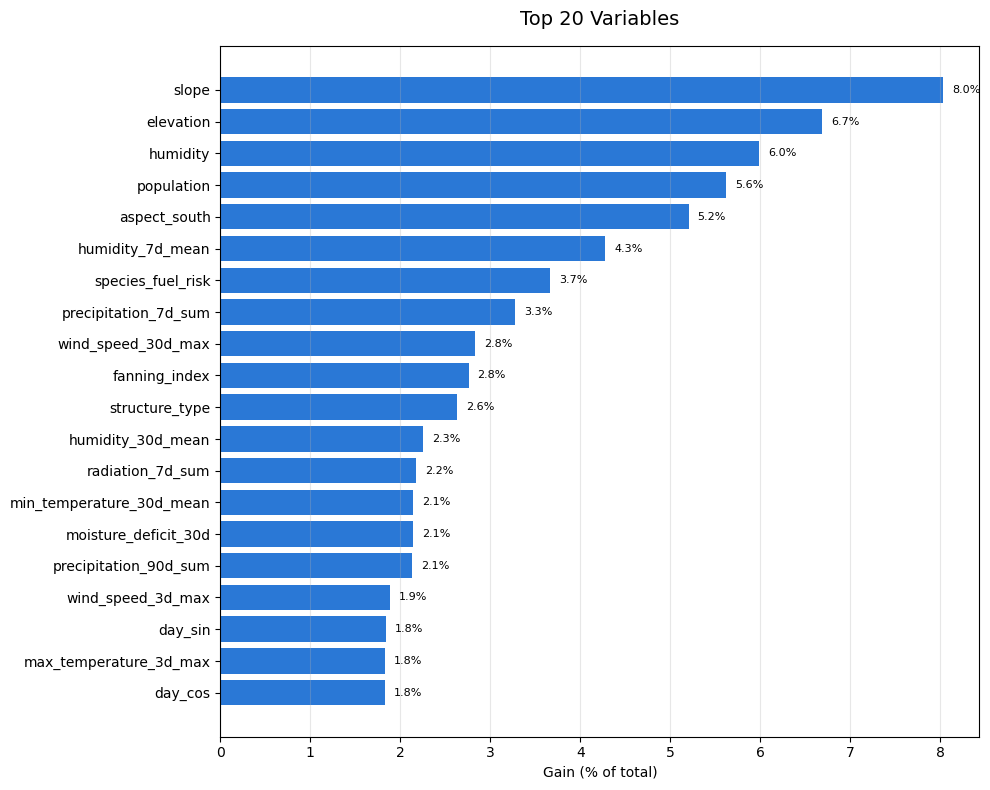

In [20]:
importance = pd.Series(
    final_model.booster_.feature_importance(importance_type='gain'),
    index=FEATURES,
).sort_values(ascending=False)

importance = importance / importance.sum() * 100 # Percentage of the total gain

top = importance.head(20)

fig, ax = plt.subplots(figsize=(10, 8))

ax.barh(top.index, top.values, color=TUNED_COLOR)

for i, value in enumerate(top.values):
    ax.text(value + 0.1, i, f"{value:.1f}%", va='center', fontsize=8)

ax.invert_yaxis() # Most important on top
ax.set_xlabel("Gain (% of total)")
ax.set_title("Top 20 Variables", fontsize=14, pad=15)
ax.grid(axis='x', alpha=0.3)

plt.tight_layout()
plt.show()